In [1]:
!pip install nflreadpy pandas matplotlib seaborn pyarrow

In [2]:
import nflreadpy as nfl
pbp = nfl.load_pbp([2025]).to_pandas()
print(pbp.shape)

ModuleNotFoundError: No module named 'nflreadpy'

In [3]:
import sys
print(sys.version)
print(sys.executable)

3.13.18 | packaged by Anaconda, Inc. | (main, Oct 27 2026, 00:49:14) [Clang 20.1.8 ]
/opt/anaconda3/envs/nfl/bin/python


In [4]:
%pip install nflreadpy pandas matplotlib seaborn pyarrow

  Using cached nflreadpy-0.1.5-py3-none-any.whl.metadata (7.5 kB)
  Using cached polars-2.1.0-py3-none-any.whl.metadata (11 kB)
  Using cached polars_runtime_32-2.1.0-cp311-abi3-macosx_11_0_arm64.whl.metadata (1.5 kB)
Using cached nflreadpy-0.1.5-py3-none-any.whl (30 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 9.6 MB/s  0:00:01 8.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 7.7 MB/s  0:00:017.8 MB/s eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 9.4 MB/s  0:00:04s eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 18.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 5.4 MB/s  0:00:0014.1 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 4.3 MB/s  0:00:01m 4.4 MB/s eta 0:00:01m
Using cached polars-2.1.0-py3-none-any.whl (911 kB)
Using cached polars_runtime_32-2.1.0-cp311-abi3-macosx_11_0_arm64.whl (47.6 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [2]:
import nflreadpy as nfl
pbp = nfl.load_pbp([2025]).to_pandas()
print(pbp.shape)

(48771, 372)


In [3]:
pbp[["posteam", "defteam", "week", "down", "ydstogo", "play_type", "yards_gained", "epa", "success"]].head(10)

,posteam,defteam,week,down,ydstogo,play_type,yards_gained,epa,success
0,NaN,NaN,1,NaN,0.0,NaN,NaN,-0.000000,0.0
1,ARI,NO,1,NaN,0.0,kickoff,0.0,-0.497133,0.0
2,ARI,NO,1,1.0,10.0,run,3.0,-0.157654,0.0
3,ARI,NO,1,2.0,7.0,pass,11.0,0.994526,1.0
4,ARI,NO,1,1.0,10.0,pass,-11.0,-1.262290,0.0
5,ARI,NO,1,2.0,21.0,run,-2.0,-0.958391,0.0
6,ARI,NO,1,3.0,23.0,run,1.0,-0.630602,0.0
7,ARI,NO,1,4.0,22.0,punt,0.0,0.443674,1.0
8,NO,ARI,1,1.0,10.0,run,3.0,-0.149376,0.0
9,NO,ARI,1,2.0,7.0,pass,0.0,-0.602408,0.0


In [4]:
runs = pbp[
    (pbp["season_type"] == "REG") &
    (pbp["rush_attempt"] == 1) &
    (pbp["qb_scramble"] == 0) &
    (pbp["posteam"].notna())
].copy()

print(runs.shape)

(13544, 372)


In [5]:
runs["epa"].describe()

count    13544.000000
mean        -0.048709
std          0.827589
min         -9.281452
25%         -0.425586
50%         -0.134251
75%          0.326683
max          5.620527
Name: epa, dtype: float64

In [6]:
team_runs = (
    runs.groupby("posteam")
    .agg(
        carries=("epa", "size"),
        epa_per_rush=("epa", "mean"),
        success_rate=("success", "mean"),
        yards_per_carry=("yards_gained", "mean"),
    )
    .reset_index()
    .sort_values("epa_per_rush", ascending=False)
)

team_runs.head(10)

,posteam,carries,epa_per_rush,success_rate,yards_per_carry
13,IND,418,0.043934,0.433014,4.389952
2,BAL,470,0.033812,0.410638,5.019149
3,BUF,497,0.029900,0.454728,4.577465
5,CHI,463,0.014987,0.468683,4.514039
6,CIN,368,0.014281,0.440217,4.119565
26,PIT,394,0.002596,0.431472,4.276650
16,LA,458,0.000949,0.475983,4.650655
8,DAL,436,-0.020151,0.422018,4.444954
19,MIA,417,-0.020863,0.407674,4.738609
23,NYG,461,-0.028815,0.394794,3.915401


FileNotFoundError: [Errno 2] No such file or directory: '../images/rush_epa_by_team.png'

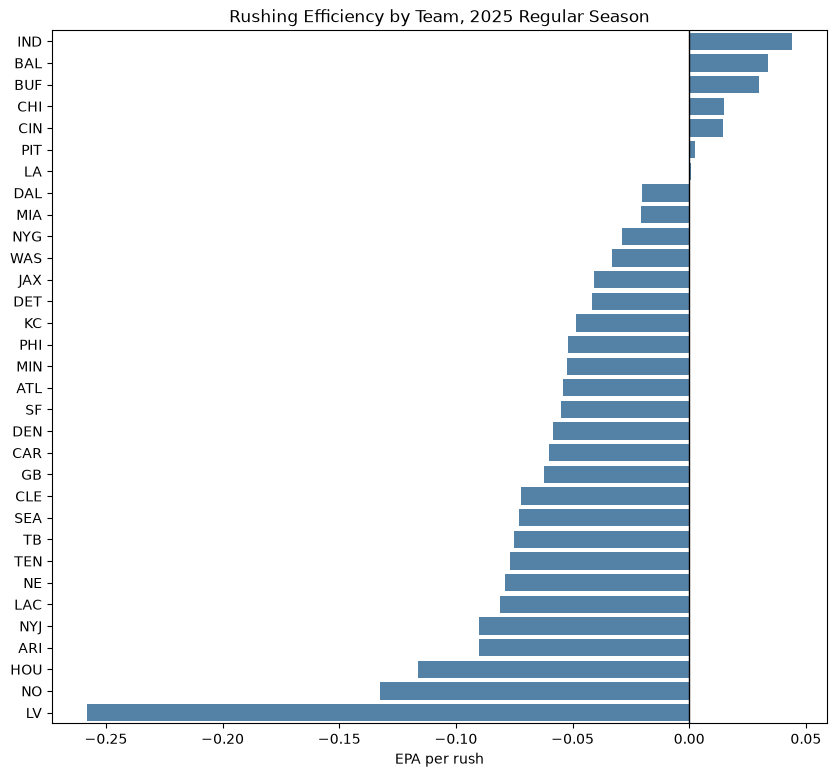

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 9))
sns.barplot(data=team_runs, y="posteam", x="epa_per_rush", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Rushing Efficiency by Team, 2025 Regular Season")
plt.xlabel("EPA per rush")
plt.ylabel("")
plt.savefig("../images/rush_epa_by_team.png", dpi=200, bbox_inches="tight")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '../images/rush_epa_by_team.png'

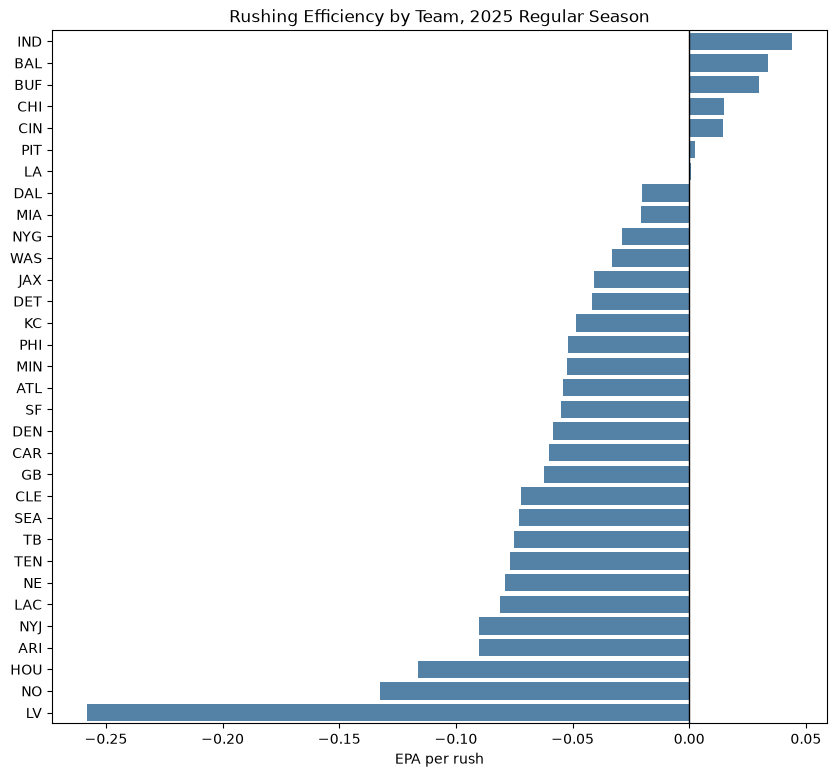

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 9))
sns.barplot(data=team_runs, y="posteam", x="epa_per_rush", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Rushing Efficiency by Team, 2025 Regular Season")
plt.xlabel("EPA per rush")
plt.ylabel("")
plt.savefig("../images/rush_epa_by_team.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
import os
print(os.getcwd())
print(os.listdir())

/Users/alexandraestevez/Documents/GitHub/nfl-run-game-analysis/notebooks
['Untitled.ipynb', 'pictures', '.ipynb_checkpoints']


FileNotFoundError: [Errno 2] No such file or directory: '../pictures/rush_epa_by_team.png'

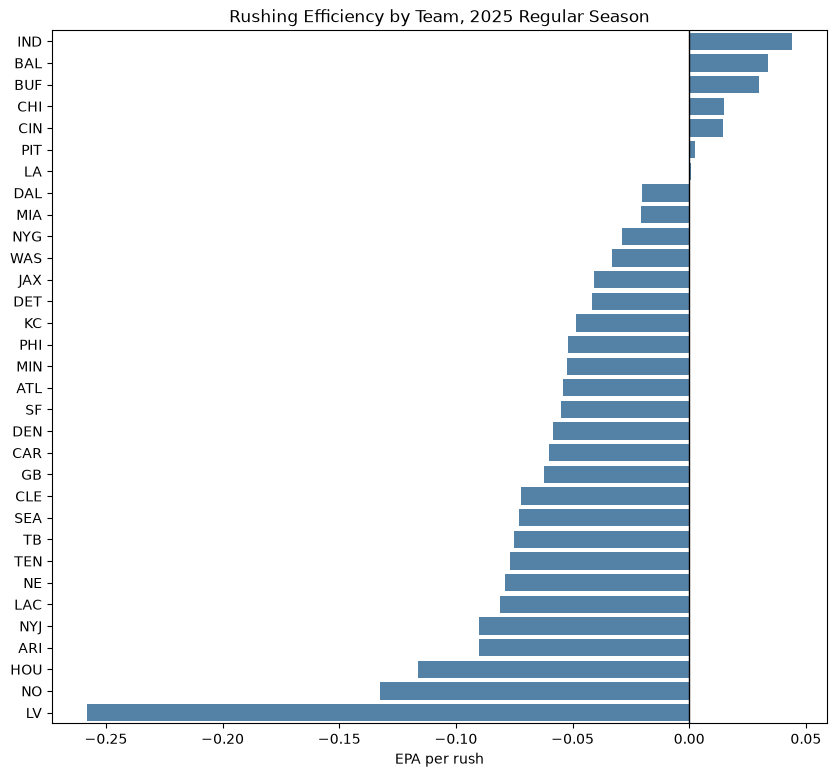

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 9))
sns.barplot(data=team_runs, y="posteam", x="epa_per_rush", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Rushing Efficiency by Team, 2025 Regular Season")
plt.xlabel("EPA per rush")
plt.ylabel("")
plt.savefig("../pictures/rush_epa_by_team.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
os.makedirs("images", exist_ok=True)
plt.savefig("images/rush_epa_by_team.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [13]:
print(os.listdir("images"))

['rush_epa_by_team.png']


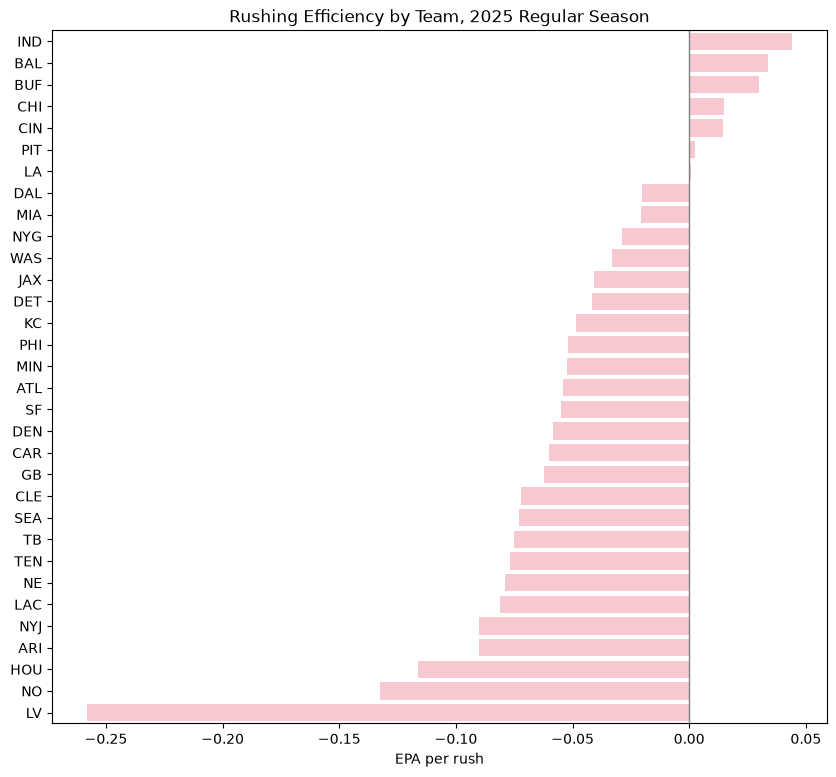

In [14]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 9))
sns.barplot(data=team_runs, y="posteam", x="epa_per_rush", color="pink")
plt.axvline(0, color="gray", linewidth=1)
plt.title("Rushing Efficiency by Team, 2025 Regular Season")
plt.xlabel("EPA per rush")
plt.ylabel("")

os.makedirs("images", exist_ok=True)
plt.savefig("images/rush_epa_by_team.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
teams_alpha = sorted(team_runs["posteam"].unique())
team_runs["team_id"] = team_runs["posteam"].map({t: i for i, t in enumerate(teams_alpha)})
team_runs["label"] = team_runs["team_id"].astype(str) + " " + team_runs["posteam"]

team_runs = team_runs.sort_values("epa_per_rush", ascending=False)
team_runs[["label", "carries", "epa_per_rush"]].head(10)

,label,carries,epa_per_rush
13,13 IND,418,0.043934
2,2 BAL,470,0.033812
3,3 BUF,497,0.029900
5,5 CHI,463,0.014987
6,6 CIN,368,0.014281
26,26 PIT,394,0.002596
16,16 LA,458,0.000949
8,8 DAL,436,-0.020151
19,19 MIA,417,-0.020863
23,23 NYG,461,-0.028815
